<a href="https://colab.research.google.com/github/Fata-Haidar/244107020108-Pembelajaran-Mesin/blob/main/JS10/lab4_js10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Langkah 1 — Import library dan dataset digits

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

digits = load_digits()
X, y = digits.data, digits.target
print('X:', X.shape, '| y:', y.shape)
print('Gambar:', digits.images.shape)

X: (1797, 64) | y: (1797,)
Gambar: (1797, 8, 8)


## Langkah 2 — Visualisasi sampel citra

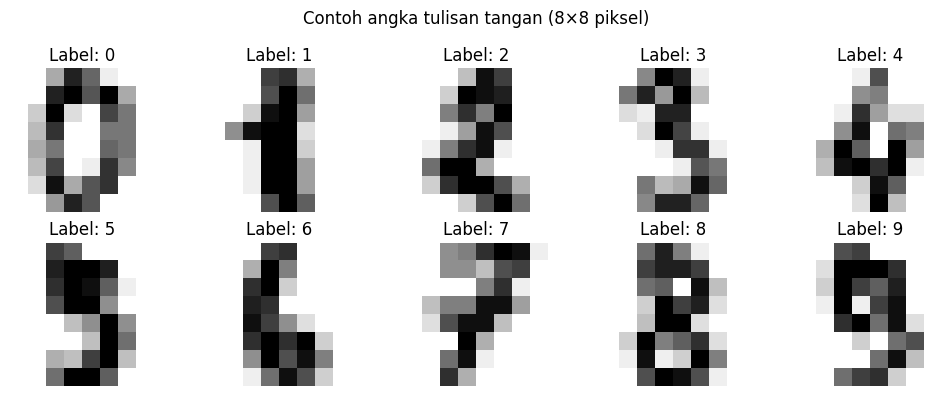

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(digits.images[i], cmap='gray_r')
    ax.set_title(f'Label: {y[i]}')
    ax.axis('off')
plt.suptitle('Contoh angka tulisan tangan (8×8 piksel)')
plt.tight_layout(); plt.show()

## Langkah 3 — Train/test split dan model ANN

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)
model = make_pipeline(StandardScaler(), MLPClassifier(
    hidden_layer_sizes=(64, 32), activation='relu', max_iter=400,
    random_state=42, early_stopping=True, n_iter_no_change=25))
model.fit(X_train, y_train)
print('Pelatihan selesai:', model.named_steps['mlpclassifier'].n_iter_, 'iterasi')

Pelatihan selesai: 62 iterasi


## Langkah 4 — Evaluasi akurasi dan confusion matrix

Akurasi data test: 96.11%
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.89      0.92      0.90        36
           2       0.92      1.00      0.96        35
           3       0.97      0.95      0.96        37
           4       0.95      1.00      0.97        36
           5       0.97      1.00      0.99        37
           6       1.00      0.94      0.97        36
           7       1.00      1.00      1.00        36
           8       0.91      0.89      0.90        35
           9       1.00      0.94      0.97        36

    accuracy                           0.96       360
   macro avg       0.96      0.96      0.96       360
weighted avg       0.96      0.96      0.96       360



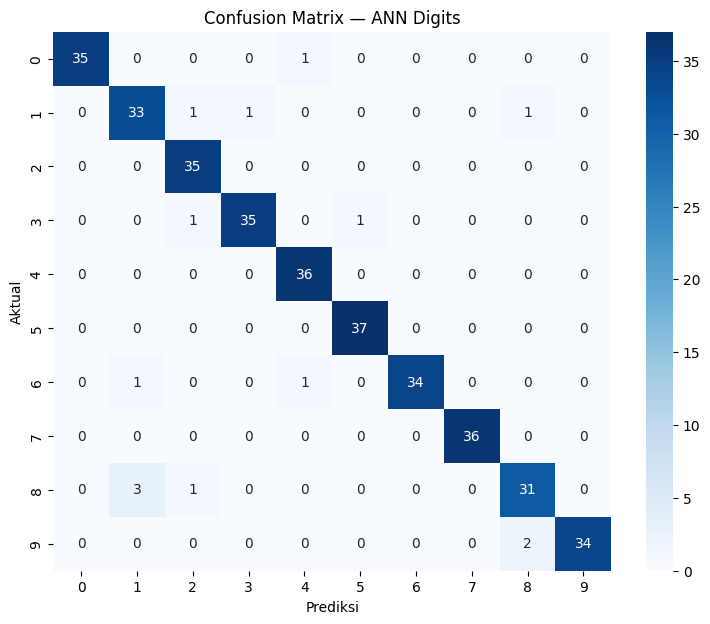

In [4]:
y_pred = model.predict(X_test)
print(f'Akurasi data test: {accuracy_score(y_test, y_pred):.2%}')
print(classification_report(y_test, y_pred, zero_division=0))
plt.figure(figsize=(9,7))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix — ANN Digits')
plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.show()

## Langkah 5 — Visualisasi hasil prediksi

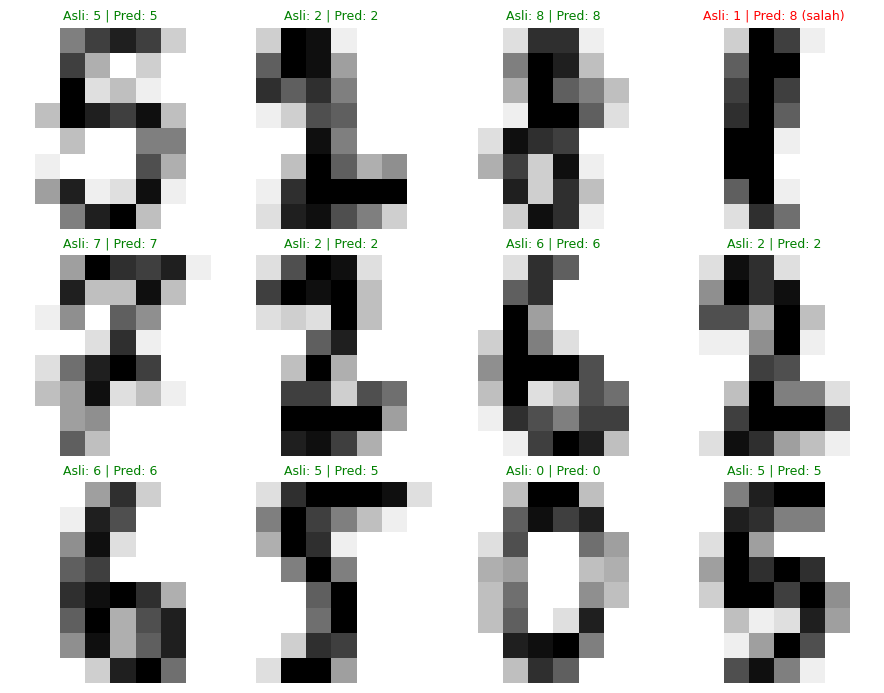

In [5]:
fig, axes = plt.subplots(3, 4, figsize=(9, 7))
for k, ax in enumerate(axes.ravel()):
    ax.imshow(X_test[k].reshape(8, 8), cmap='gray_r')
    ok = y_pred[k] == y_test[k]
    ax.set_title(f'Asli: {y_test[k]} | Pred: {y_pred[k]}' + ('' if ok else ' (salah)'),
                 color='green' if ok else 'red', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

## Langkah 6 — Grafik learning curve

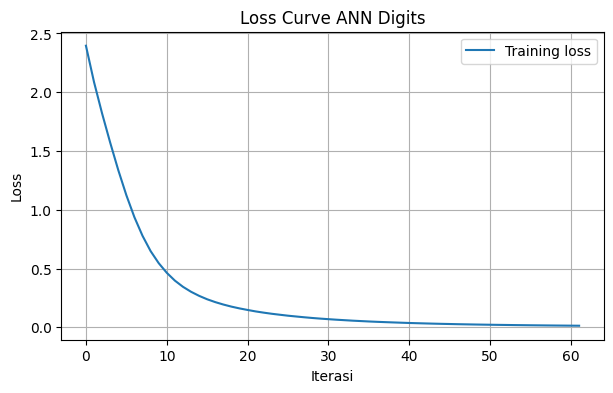

In [6]:
hist = model.named_steps['mlpclassifier'].loss_curve_
plt.figure(figsize=(7,4))
plt.plot(hist, label='Training loss')
plt.xlabel('Iterasi'); plt.ylabel('Loss'); plt.title('Loss Curve ANN Digits')
plt.legend(); plt.grid(True); plt.show()

## Kesimpulan

Setiap gambar 8×8 diubah menjadi 64 fitur numerik. ANN dengan hidden layer mempelajari pola piksel untuk mengenali sepuluh kelas. **Akurasi data test** dan *confusion matrix* membantu menilai kemampuan model pada sampel yang belum pernah dilihat.